#### Forecast experiment 1 - Sine wave, version 2
This version uses actual train/val/test -split for data + TensorFlow datasets instead of the deprecated generators.


In [22]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn import metrics
from sklearn.metrics import mean_absolute_percentage_error
import keras
import seaborn as sns

# in time series forecasting, we usually need to scale our values
# for better end results
from sklearn.preprocessing import MinMaxScaler

# lock down the random seed, to ensure reproducibility of results
# seed = 2026
seed = 91
keras.utils.set_random_seed(seed)

In [23]:
# Load the Dataset
df = pd.read_csv("gold_price_data.csv")

df = df.iloc[:2290]   # keep only the original rows, drop the 210 synthetic ones at the end

In [24]:
df

,Date,SPX,GLD,USO,SLV,EUR/USD
0,2008-01-02,1447.160034,84.860001,78.470001,15.1800,1.471692
1,2008-01-03,1447.160034,85.570000,78.370003,15.2850,1.474491
2,2008-01-04,1411.630005,85.129997,77.309998,15.1670,1.475492
3,2008-01-07,1416.180054,84.769997,75.500000,15.0530,1.468299
4,2008-01-08,1390.189941,86.779999,76.059998,15.5900,1.557099
...,...,...,...,...,...,...
2285,2018-05-08,2671.919922,124.589996,14.060000,15.5100,1.186789
2286,2018-05-09,2697.790039,124.330002,14.370000,15.5300,1.184722
2287,2018-05-10,2723.070068,125.180000,14.410000,15.7400,1.191753
2288,2018-05-14,2730.129883,124.489998,14.380000,15.5600,1.193118


In [25]:
# for easier and more dynamic code, save the value column name here
value_column = 'GLD'

#### Before going any further, scale the values in our DataFrame

In [26]:
# scale the values with MinMaxScaler so that we don't
# affect the distribution of data (thus making the signal not realistic anymore)
# MinMaxScaler is a good solution here
scaler = MinMaxScaler()
df[[value_column]] = scaler.fit_transform(df[[value_column]])

# as weird as it sounds, scaling the index/sequence number also
# to be a decimal might affect the performance of the network
df = df.drop("Date", axis=1)
# df.index = df.index * 0.1 + 1

In [27]:
df

,SPX,GLD,USO,SLV,EUR/USD
0,1447.160034,0.129680,78.470001,15.1800,1.471692
1,1447.160034,0.135876,78.370003,15.2850,1.474491
2,1411.630005,0.132036,77.309998,15.1670,1.475492
3,1416.180054,0.128894,75.500000,15.0530,1.468299
4,1390.189941,0.146435,76.059998,15.5900,1.557099
...,...,...,...,...,...
2285,2671.919922,0.476394,14.060000,15.5100,1.186789
2286,2697.790039,0.474125,14.370000,15.5300,1.184722
2287,2723.070068,0.481543,14.410000,15.7400,1.191753
2288,2730.129883,0.475521,14.380000,15.5600,1.193118


In [28]:
# let's figure out a good cutoff point for train/test
# 80% for training, 20% testing (NOTE: you should experiment on this to find optimal %)
cutoff = int(len(df) * 0.8)

# train data
X_train = df.index[0:cutoff]
y_train = df[value_column].iloc[0:cutoff]

# test data
X_test = df.index[cutoff:]
y_test = df[value_column].iloc[cutoff:]

# convert everything into NumPy -array format
X_train = np.array(X_train)
y_train = np.array(y_train)
X_test = np.array(X_test)
y_test = np.array(y_test)

# in this case, number of variables is 1 => scaled passengers value
n_features = 1

# use reshape tools to get the data ready for future use
train_series = y_train.reshape((len(y_train), n_features))
test_series  = y_test.reshape((len(y_test), n_features))

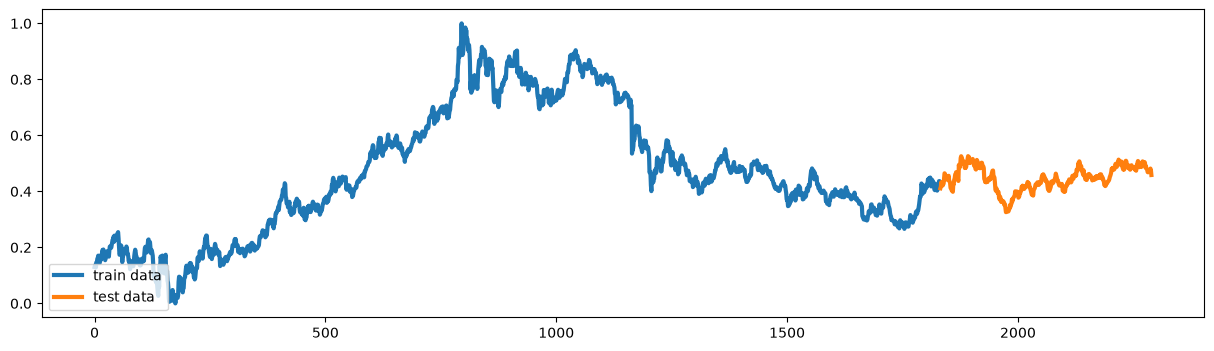

In [29]:
fig, ax = plt.subplots(1, 1, figsize=(15, 4))
ax.plot(X_train,y_train, lw=3, label='train data')
ax.plot(X_test, y_test,  lw=3, label='test data')
ax.legend(loc="lower left")
plt.show()

#### Train/test datasets with generators

In [30]:
from tensorflow.keras.utils import timeseries_dataset_from_array

# the variable that determines how many points
# back into the past the model attempts to learn
look_back  = 90
batch_size = 32
window_size = 1

# stride = 1 => means we use separate time steps
# more than 1 => we use windowing

# THIS IS USING THE MORE MODERN TENSORFLOW DATASETS
# INSTEAD OF THE ORIGINAL TIMESERIES GENERATORS
# TimeseriesGenerator is deprecated and will be removed in future
# Tensorflow versions, but nobody knows exactly when that happens

# unfortunately, the TF datasets and the original TimeseriesGenerators
# do the same thing in THEORY, but in practice, they function in a different
# manner when feeding the training data into the neural network while training

train_generator = timeseries_dataset_from_array(
    data=train_series,
    targets=train_series[look_back:],
    sequence_length=look_back,
    sampling_rate=1,
    sequence_stride=window_size,
    batch_size=batch_size,
    shuffle=False,
)

test_generator = timeseries_dataset_from_array(
    data=test_series,
    targets=test_series[look_back:],
    sequence_length=look_back,
    sampling_rate=1,
    sequence_stride=window_size,
    batch_size=batch_size,
    shuffle=False,
)

#### Create neural network

In [31]:
from keras.models import Sequential
from keras import Input
from keras.layers import LSTM, SimpleRNN
from keras.layers import Dense, Dropout
from keras.callbacks import ModelCheckpoint

# create a model checkpoint to a file, and only save the best one
mc = ModelCheckpoint('best_model_gold_price.keras', monitor='val_loss', mode='min', save_best_only=True)
callback_list = [mc]

# build the neural network
# in this case, LSTM with 64 neurons
n_neurons  = 64

model = Sequential()
model.add(Input(shape=(look_back, n_features)))
model.add(LSTM(n_neurons))

# alternatively, we might try adding regularization here as well
# so add to the Dense-layer => kernel_regularizer=keras.regularizers.l1(l1=0.1)
# might need some experimentation, whether L1, L2 or L1/L2 is the best one
# and if you need to increase the regularization rate to be above 0.1
model.add(Dense(16, activation="relu"))

# due to the differences how TF datasets and Timeseries Generators 
# actually work and feed the data to the neural network
# you usually need to increase regularization when switching to TF datasets
model.add(Dropout(0.1))

model.add(Dense(1))
from keras.optimizers import Adam
model.compile(optimizer=Adam(learning_rate=0.0003), loss='mse')

# it's not optimal to use test data as validation data
# because this might skew our metrics
# see the other version of this notebook on how to do
# train/validation/test -split for the sine wave
model.fit(train_generator, epochs=120, verbose=1, validation_data=test_generator, callbacks=callback_list)

Epoch 1/120


c:\Users\Gayani\Deep_Learning\Deep_Learning\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


55/55 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - loss: 0.0432 - val_loss: 0.0053
Epoch 2/120
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0178 - val_loss: 0.0037
Epoch 3/120
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0188 - val_loss: 0.0039
Epoch 4/120
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0147 - val_loss: 0.0037
Epoch 5/120
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0162 - val_loss: 0.0038
Epoch 6/120
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0156 - val_loss: 0.0033
Epoch 7/120
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0145 - val_loss: 0.0021
Epoch 8/120
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0155 - val_loss: 0.0024
Epoch 9/120
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0134 - val_loss: 0.0025
Epoch 10/120
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0122 - val_loss: 0.0022
Epoch 11/120
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0114 - val_loss: 0.0016
Epoch 12/120
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0

#### Training metrics

<Axes: >

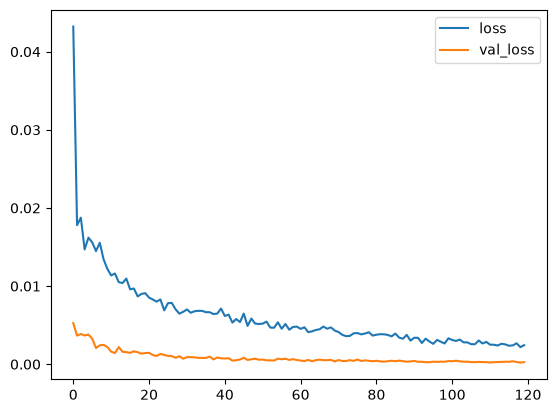

In [32]:
# the usual training metrics visualization
loss_df = pd.DataFrame(model.history.history)
loss_df.plot()

In [33]:
# reload the best version of the model
from keras.models import load_model
model = load_model("best_model_gold_price.keras")

In [34]:
# TensorFlow evaluation metrics
result = model.evaluate(train_generator)
print(f"Training loss: {result}")

# test loss
result = model.evaluate(test_generator)
print(f"Testing loss: {result}")

# these values are not very close to each other, 
# which means my model is not quite optimal
# IN THEORY 

55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0010  
Training loss: 0.001029443577863276
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 2.1221e-04 
Testing loss: 0.00021221154020167887


#### Test predictions

In [35]:
test_predictions  = model.predict(test_generator)

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


#### Conventional regression metrics + MAPE

In [36]:
# let's make a separate copy of the test values
# so we can calculate some errors

actual_y_test = np.concatenate([y for x, y in test_generator])
errors = np.abs(actual_y_test - test_predictions)
mape = mean_absolute_percentage_error(actual_y_test, test_predictions) * 100

# print out the MAPE-score
print("MAPE (mean average precision error):")
print(f"{round(mape, 2)} %")

# MAE - Mean average error
print("\nMAE")
print(round(metrics.mean_absolute_error(actual_y_test, test_predictions), 2), "units")

# MSE - Mean square error
print("\nMSE")
print(round(metrics.mean_squared_error(actual_y_test, test_predictions), 2), "units^2")

# RMSE - Root mean square error
print('\nRMSE:')
print(round(np.sqrt(metrics.mean_squared_error(actual_y_test, test_predictions)), 2), "units")

# R-squared. 0 = the model descibes the dataset poorly
# 1 = model describes the dataset perfectly
print('\nR-squared:')
print(round(metrics.r2_score(actual_y_test, test_predictions), 2))

MAPE (mean average precision error):
2.69 %

MAE
0.01 units

MSE
0.0 units^2

RMSE:
0.01 units

R-squared:
0.88


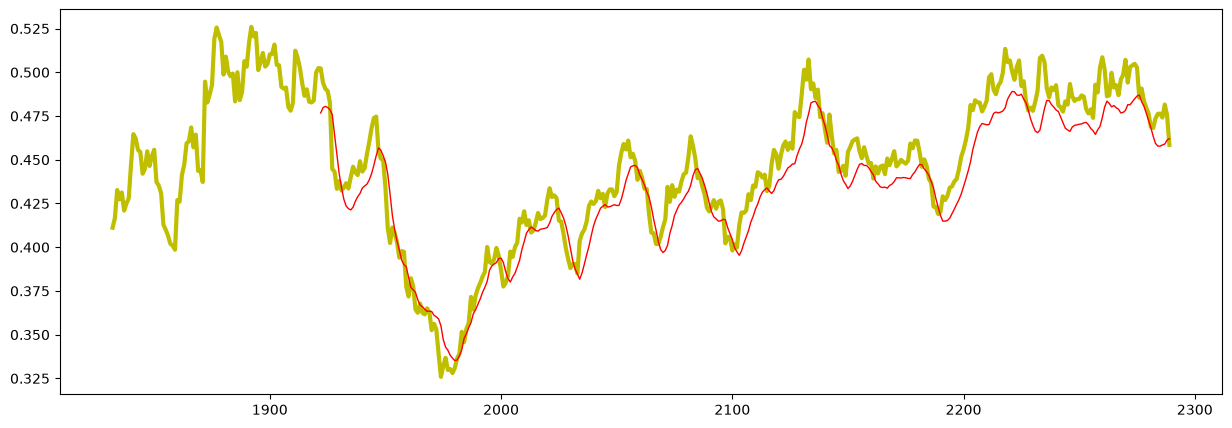

In [37]:
# calculate helper x-variables for where the train data starts
# where the test data starts and where the predictions start
x1 = np.arange(0, len(y_train))
x2 = np.arange(len(y_train), len(y_train) + len(y_test))
x3 = np.arange(len(y_train) + look_back, len(y_train) + len(y_test))

fig, ax = plt.subplots(1, 1, figsize=(15, 5))
# ax.plot(x1, y_train, lw=2, label='train data')
ax.plot(x2, y_test, lw=3, c='y', label='test data')
ax.plot(x3, test_predictions, lw=1, c='r', label='predictions')
# ax.legend(loc="lower left")
plt.show()

In [38]:
# TensorFlow evaluation metrics
result = model.evaluate(train_generator)
print(f"Training loss: {result}")

# test loss
result = model.evaluate(test_generator)
print(f"Testing loss: {result}")

# some difference here which we can see in the test-signal prediction already 

55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0010  
Training loss: 0.001029443577863276
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 2.1221e-04 
Testing loss: 0.00021221154020167887


#### Extrapolation into the future

In [39]:
# EXTRAPOLATION TEST 1 - 180 new points
extrapolation = list()
seed_batch    = y_test[:look_back].reshape((1,look_back, n_features))
current_batch = seed_batch

# extrapolate the next 180 values
for i in range(180):
    predicted_value = model.predict(current_batch, verbose=None)[0]
    extrapolation.append(predicted_value) 
    current_batch = np.append(current_batch[:,1:,:],[[predicted_value]],axis=1)

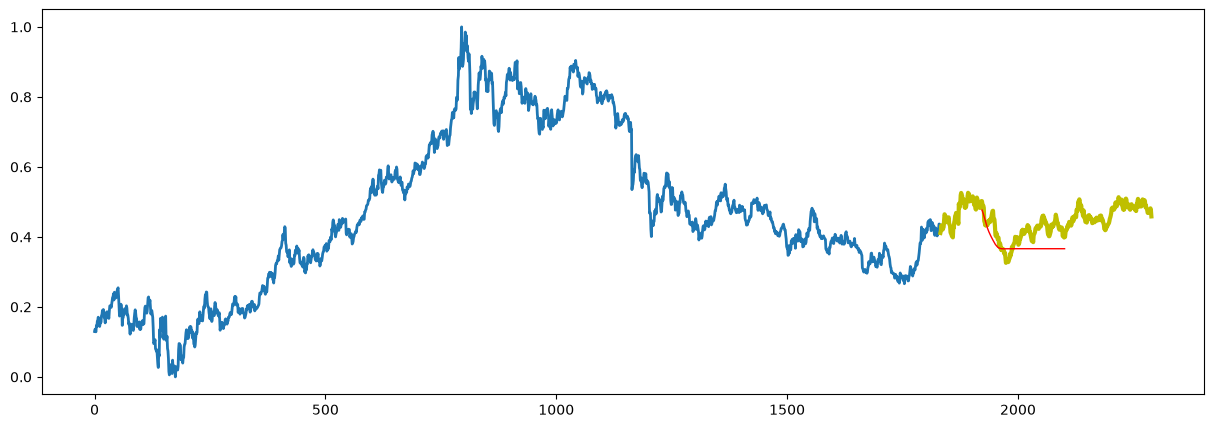

In [40]:
x1 = np.arange(0, len(y_train))
x2 = np.arange(len(y_train), len(y_train) + len(y_test))
x3 = np.arange(len(y_train) + look_back, len(y_train) + len(extrapolation) + look_back)

fig, ax = plt.subplots(1, 1, figsize=(15, 5))
ax.plot(x1, y_train, lw=2, label='train data')
ax.plot(x2, y_test, lw=3, c='y', label='test data')
ax.plot(x3, extrapolation, lw=1, c='r', label='predictions')
# ax.legend(loc="lower left")
plt.show()

#### Step 6: Does the forecast look realistic?

No. In the extrapolation plot the red line is almost flat at about 0.45, while the real gold price moves up and down. Each new prediction is fed back in as input, so the model reads its own smooth guesses instead of real data. Small errors pile up, and the forecast settles on one "typical" value and stays there. The further it goes, the less it tells anything.

#### Step 7: Analysis

The dataset has daily prices for SPX, GLD, USO, SLV and EUR/USD. I forecast GLD (gold). 210 of the 2500 rows were synthetic data at the end of the file, and they ruined my first results (R² below zero), so I removed them with df.iloc[:2290].

The network is an LSTM with 64 units, a Dense layer with 16 units, Dropout 0.2, and a Dense(1) output. It uses Adam and MSE, and ModelCheckpoint saves the epoch with the lowest validation loss. With activation="relu` in the LSTM my training collapsed (the loss went up and stayed flat), and removing it fixed that.

Both losses fall quickly and stay low. MAPE is 3.4% and R² is 0.8, so the predictions follow the real price quite well. The red line is smoother than the real one and misses the highest peaks and lowest dips. The training loss (0.020) is much higher than the test loss (0.00036), so the two are not "very close"

It becomes a flat line, as described above, so the model is useful for one step ahead but not for long-term forecasting.


**Limitations.** The model only knows past values, not news or other causes. Forecast errors grow with the horizon. Financial prices are close to random, so they are hard to predict.

**Optimizations.** May be I have to Try different look_back, number of neurons and split percentages, one at a time. 